Reading power logs from: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/power_logs/llama_1b
Saving plots to: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/llama_1b
tp1_pp1_dp4: avg=772.4W  steady=872.0W  samples=847
tp4_pp1_dp1: avg=540.1W  steady=562.1W  samples=1920
tp1_pp4_dp1: avg=672.8W  steady=734.3W  samples=1044
tp2_pp2_dp1: avg=579.3W  steady=615.4W  samples=1456
tp2_pp1_dp2: avg=665.4W  steady=725.6W  samples=1118
tp1_pp2_dp2: avg=757.8W  steady=853.0W  samples=868
hybrid_schedule [SCHED]: avg=584.0W  steady=628.9W  samples=1495

CI schedule duration (derived): 960.0s (slowest = tp4_pp1_dp1)
Each of the 3 periods covers 320.0s of wall-clock time.

Label                |   Time |   Power |  Energy |   C_fix |   C_var |      Tput
----------------------------------------------------------------------------------
DP=4                 | 423.5s |  772.4W |  90.86Wh |  36.3g |  29.0g |  7737.4 t/s
TP=4                 | 960.0s |  540.1W

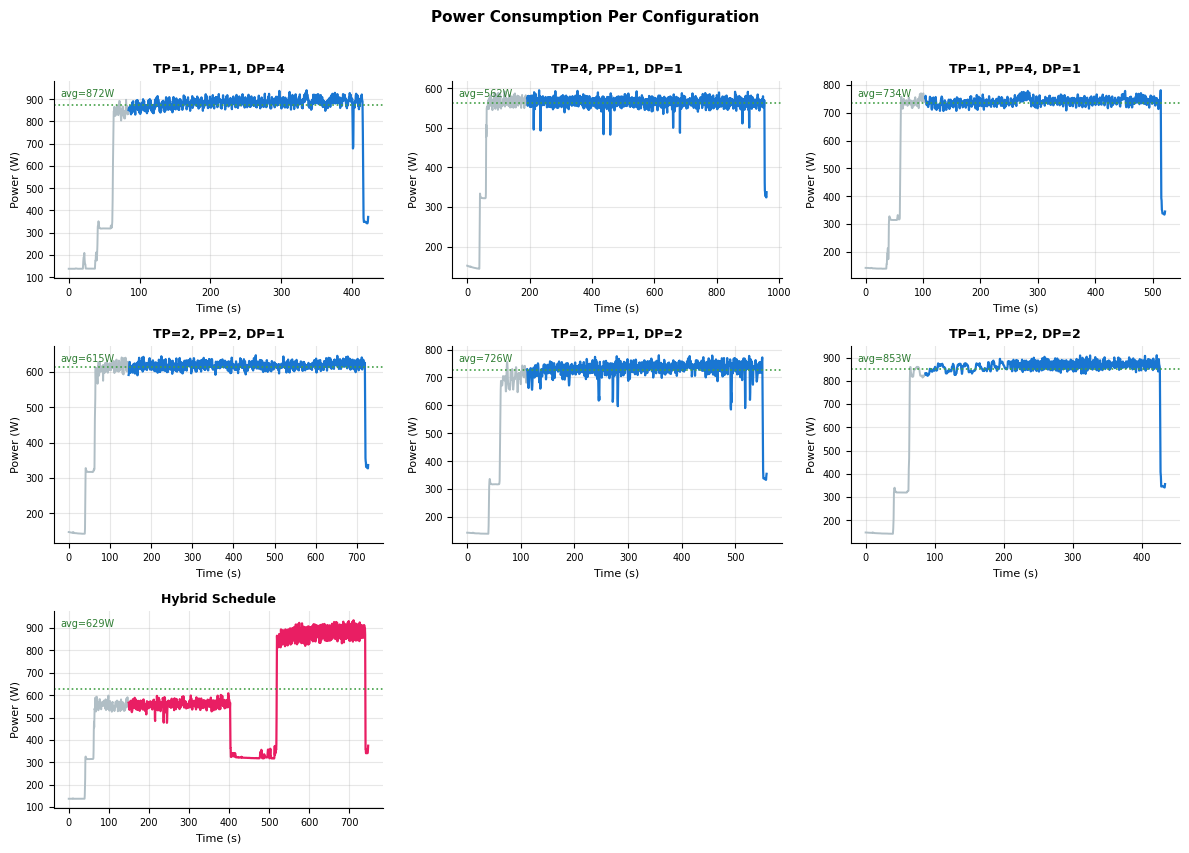


CI SCHEDULE:  A = [400, 100, 100] gCO₂/kWh over 960s
  Period 1: 0–320s → 400 g/kWh (high)
  Period 2: 320–640s → 100 g/kWh (low)
  Period 3: 640–960s → 100 g/kWh (low)
Fixed baseline: 400 gCO₂/kWh


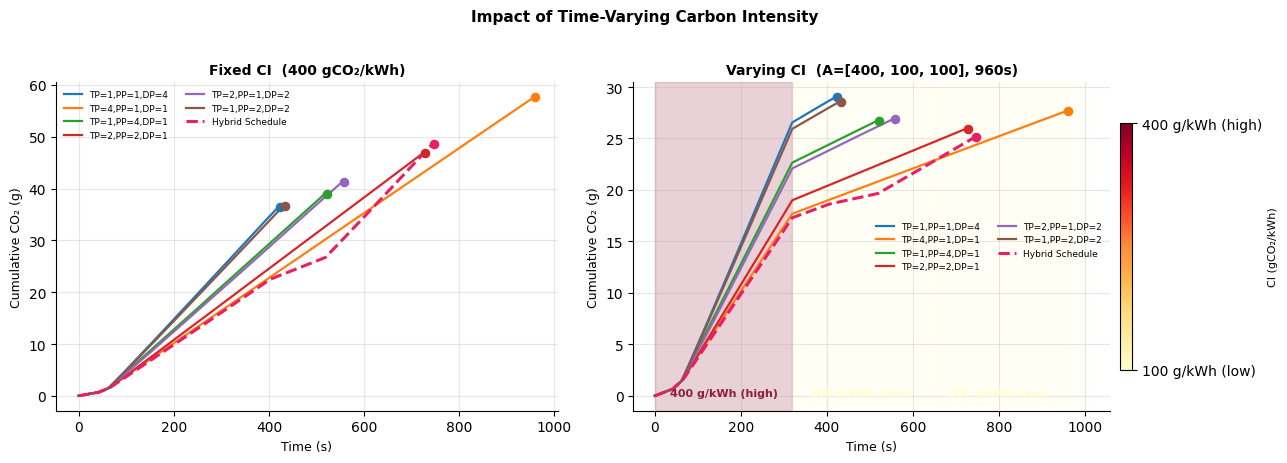

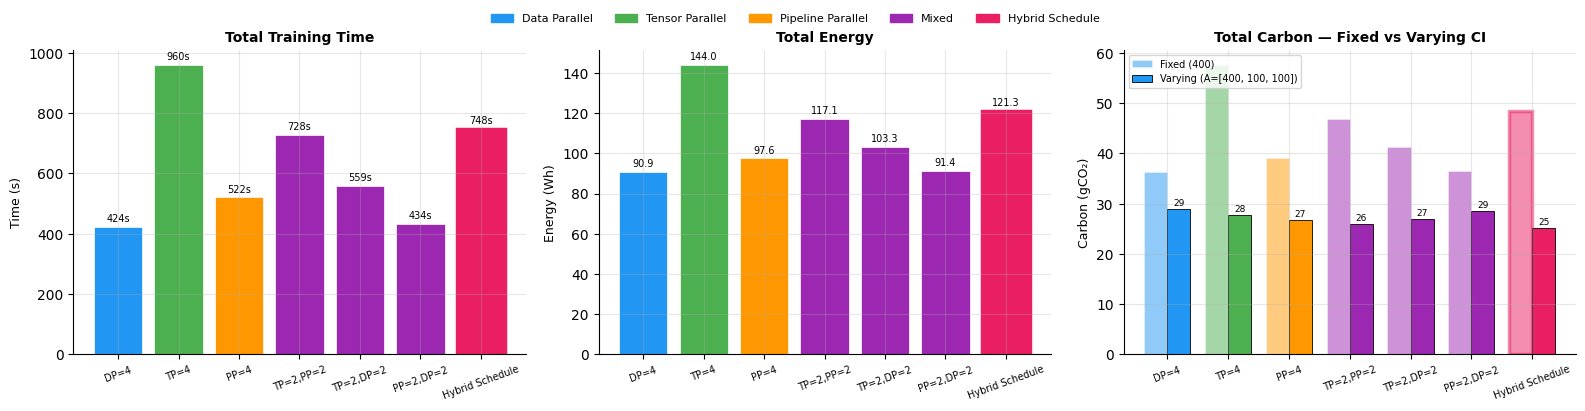

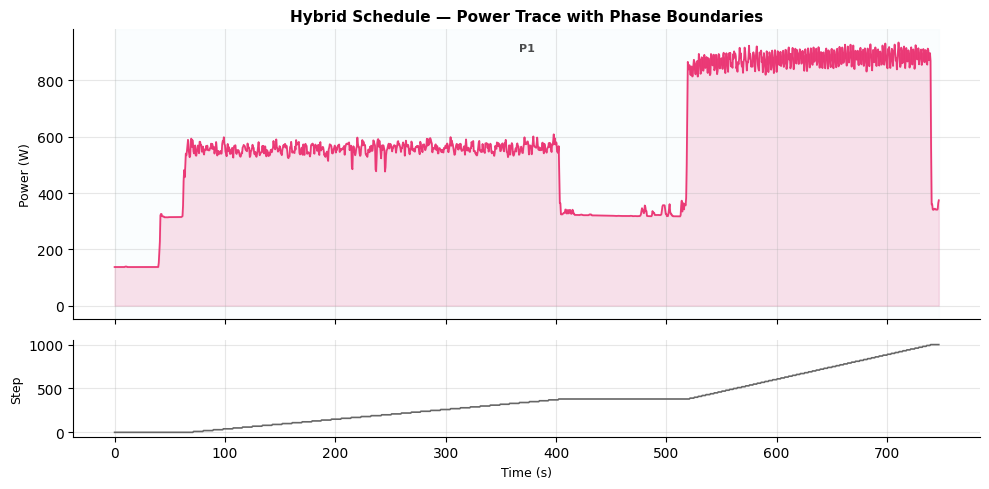


SUMMARY TABLE
         Config     Type  Time(s)  Avg Power(W)  Energy(Wh)  C_Fixed@400(g)  C_Vary(g)  Tput(tok/s)
           DP=4   Static    423.5         772.4       90.86           36.34      29.00       7737.4
           TP=4   Static    960.0         540.1      144.02           57.61      27.67       3413.3
           PP=4   Static    522.0         672.8       97.55           39.02      26.75       6277.4
      TP=2,PP=2   Static    728.0         579.3      117.14           46.86      25.96       4501.1
      TP=2,DP=2   Static    559.0         665.4      103.32           41.33      26.90       5861.9
      PP=2,DP=2   Static    434.0         757.8       91.36           36.54      28.59       7550.2
Hybrid Schedule Schedule    747.5         584.0      121.26           48.50      25.10       4383.7

Saved: /afs/cs.pitt.edu/usr0/wat29/scheduling-carbon-aware-3d-parallelism/plots/llama_1b/summary_table.csv


In [21]:
# Visualization Notebook — compact edition
#
# Analyzes power logs from 3D parallelism benchmarks (static + hybrid).
# CI schedule is wall-clock-based: all configs share the same CI timeline.
# Schedule duration is auto-derived from the slowest run.

# =====================================================================
# 1) Imports and Plot Style
# =====================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

COLORS = {
    "dp": "#2196F3", "tp": "#4CAF50", "pp": "#FF9800",
    "mixed": "#9C27B0", "schedule": "#E91E63",
}

# =====================================================================
# 2) Configuration
# =====================================================================
BASE = os.getcwd()
MODEL_NAME = "llama_1b"
DATA_DIR = os.path.join(BASE, "power_logs", MODEL_NAME)
PLOTS_DIR = os.path.join(BASE, "plots", MODEL_NAME)
os.makedirs(PLOTS_DIR, exist_ok=True)
print(f"Reading power logs from: {DATA_DIR}")
print(f"Saving plots to: {PLOTS_DIR}")

INTERVAL_SECONDS = 0.5
TRAIN_ITERS = 200
GLOBAL_BATCH = 16
SEQ_LEN = 1024

A = [400, 100, 100]   # CI per period (gCO₂/kWh)
CI_FIXED = 400    # baseline constant
# CI_SCHEDULE_DURATION_S is derived below from the slowest run.

# =====================================================================
# 3) Helper Functions
# =====================================================================

def load_power_csv(path):
    df = pd.read_csv(path)
    df.columns = [c.strip() for c in df.columns]
    if "time_step" not in df.columns:
        df.columns = ["timestamp", "total_power_W",
                      "GPU_0_W", "GPU_1_W", "GPU_2_W", "GPU_3_W"]
        df["time_step"] = 0
    return df


def get_ci_schedule_wallclock(n_samples, interval, A, schedule_duration_s):
    ci = np.full(n_samples, A[-1], dtype=float)
    period_s = schedule_duration_s / len(A)
    for i, c in enumerate(A):
        idx_start = max(0, min(int(i * period_s / interval), n_samples))
        idx_end   = max(0, min(int((i + 1) * period_s / interval), n_samples))
        ci[idx_start:idx_end] = c
    return ci


def compute_carbon(power_samples, ci_array, interval=0.5):
    energy_kwh = power_samples * interval / 3_600_000
    grams = energy_kwh * ci_array
    return np.cumsum(grams), grams.sum()


# ── CI color mapping ─────────────────────────────────────────
_CI_CMAP = plt.cm.YlOrRd
_CI_NORM = None

def build_ci_norm(A):
    global _CI_NORM
    ci_min, ci_max = min(A), max(A)
    if ci_max == ci_min:
        _CI_NORM = mcolors.Normalize(vmin=ci_min * 0.9, vmax=ci_max * 1.1)
    else:
        _CI_NORM = mcolors.Normalize(vmin=ci_min, vmax=ci_max)

def ci_to_color(ci_val):
    if _CI_NORM is None:
        raise RuntimeError("Call build_ci_norm(A) first.")
    return _CI_CMAP(_CI_NORM(ci_val))

def ci_label(ci_val, A):
    ci_min, ci_max = min(A), max(A)
    if ci_val == ci_max and ci_val != ci_min:
        return f"{ci_val} g/kWh (high)"
    if ci_val == ci_min and ci_val != ci_max:
        return f"{ci_val} g/kWh (low)"
    return f"{ci_val} g/kWh"

build_ci_norm(A)

def add_ci_colorbar(fig, ax, A, label="CI (gCO₂/kWh)"):
    sm = plt.cm.ScalarMappable(cmap=_CI_CMAP, norm=_CI_NORM)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=ax, orientation="vertical",
                      fraction=0.03, pad=0.02, shrink=0.75)
    cb.set_label(label, fontsize=8)
    cb.set_ticks(sorted(set(A)))
    cb.set_ticklabels([ci_label(c, A) for c in sorted(set(A))])
    return cb


def _classify(cfg):
    if cfg["is_schedule"]:
        return "schedule"
    dims_gt1 = sum(1 for d in (cfg["tp"], cfg["pp"], cfg["dp"]) if d > 1)
    if dims_gt1 >= 2: return "mixed"
    if cfg["tp"] > 1: return "tp"
    if cfg["pp"] > 1: return "pp"
    return "dp"


def _label(cfg):
    if cfg["is_schedule"]:
        return "Hybrid\nSchedule"
    parts = []
    if cfg["tp"] > 1: parts.append(f"TP={cfg['tp']}")
    if cfg["pp"] > 1: parts.append(f"PP={cfg['pp']}")
    if cfg["dp"] > 1: parts.append(f"DP={cfg['dp']}")
    return ",".join(parts) if parts else "DP=1"


def annotate_ci_periods(ax, A, schedule_duration_s, y_label_frac=0.04):
    period_s = schedule_duration_s / len(A)
    ylo, yhi = ax.get_ylim()
    y_text = ylo + (yhi - ylo) * y_label_frac
    for i, c in enumerate(A):
        x0, x1 = i * period_s, (i + 1) * period_s
        ax.axvspan(x0, x1, alpha=0.18, color=ci_to_color(c), zorder=0)
        ax.text((x0 + x1) / 2, y_text, ci_label(c, A),
                ha="center", va="bottom", fontsize=8,
                fontweight="bold", color=ci_to_color(c), alpha=0.85)
    xlim = ax.get_xlim()
    if xlim[1] > schedule_duration_s:
        ax.axvspan(schedule_duration_s, xlim[1], alpha=0.10,
                   color=ci_to_color(A[-1]), zorder=0)

# =====================================================================
# 4) Load CSVs and Compute Power Statistics
# =====================================================================
all_possible_configs = {
    "tp1_pp1_dp4": {"tp": 1, "pp": 1, "dp": 4, "file": "elastic_tp1_pp1_dp4_power.csv", "is_schedule": False},
    "tp4_pp1_dp1": {"tp": 4, "pp": 1, "dp": 1, "file": "elastic_tp4_pp1_dp1_power.csv", "is_schedule": False},
    "tp1_pp4_dp1": {"tp": 1, "pp": 4, "dp": 1, "file": "elastic_tp1_pp4_dp1_power.csv", "is_schedule": False},
    "tp2_pp2_dp1": {"tp": 2, "pp": 2, "dp": 1, "file": "elastic_tp2_pp2_dp1_power.csv", "is_schedule": False},
    "tp2_pp1_dp2": {"tp": 2, "pp": 1, "dp": 2, "file": "elastic_tp2_pp1_dp2_power.csv", "is_schedule": False},
    "tp1_pp2_dp2": {"tp": 1, "pp": 2, "dp": 2, "file": "elastic_tp1_pp2_dp2_power.csv", "is_schedule": False},
}

schedule_configs_def = {
    "hybrid_schedule": {
        "tp": None, "pp": None, "dp": None,
        "file": "elastic_example_schedule_power.csv",
        "is_schedule": True,
    },
}

configs = {}
skipped = []

for name, cfg in {**all_possible_configs, **schedule_configs_def}.items():
    path = os.path.join(DATA_DIR, cfg["file"])
    if not os.path.exists(path):
        skipped.append(name)
        continue
    df = load_power_csv(path)
    if len(df) < 2:
        skipped.append(name)
        continue
    warmup = int(len(df) * 0.2)
    steady = df.iloc[warmup:]
    cfg["avg_power"] = df["total_power_W"].mean()
    cfg["steady_avg_power"] = steady["total_power_W"].mean()
    cfg["peak_power"] = df["total_power_W"].max()
    cfg["df"] = df
    configs[name] = cfg
    tag = " [SCHED]" if cfg["is_schedule"] else ""
    print(f"{name}{tag}: avg={cfg['avg_power']:.1f}W  "
          f"steady={cfg['steady_avg_power']:.1f}W  samples={len(df)}")

if skipped:
    print(f"\nSkipped: {', '.join(skipped)}")

static_configs = {k: v for k, v in configs.items() if not v["is_schedule"]}
sched_configs  = {k: v for k, v in configs.items() if v["is_schedule"]}
n_configs = len(configs)
all_configs = [(_label(cfg), _classify(cfg), cfg) for _, cfg in configs.items()]

# =====================================================================
# 4b) Derive CI schedule duration from the slowest run
# =====================================================================
# The CI schedule spans from t=0 until the last strategy finishes.
# This divides A equally across the full training window — no manual tuning.
if not configs:
    raise RuntimeError("No configs loaded — cannot derive schedule duration.")

CI_SCHEDULE_DURATION_S = max(len(cfg["df"]) for cfg in configs.values()) * INTERVAL_SECONDS
slowest = max(configs.items(), key=lambda kv: len(kv[1]["df"]))[0]
print(f"\nCI schedule duration (derived): {CI_SCHEDULE_DURATION_S:.1f}s "
      f"(slowest = {slowest})")
print(f"Each of the {len(A)} periods covers "
      f"{CI_SCHEDULE_DURATION_S / len(A):.1f}s of wall-clock time.")

# =====================================================================
# 5) Compute Metrics
# =====================================================================
total_tokens = TRAIN_ITERS * GLOBAL_BATCH * SEQ_LEN

print(f"\n{'Label':20s} | {'Time':>6s} | {'Power':>7s} | "
      f"{'Energy':>7s} | {'C_fix':>7s} | {'C_var':>7s} | {'Tput':>9s}")
print("-" * 82)

for label, _, cfg in all_configs:
    power = cfg["df"]["total_power_W"].to_numpy()
    n = len(power)
    total_time_s = n * INTERVAL_SECONDS
    cfg["train_time_s"] = total_time_s
    cfg["total_time_s"] = total_time_s
    cfg["avg_power_w"] = power.mean()
    cfg["total_energy_wh"] = power.sum() * INTERVAL_SECONDS / 3600
    cfg["tokens_per_sec"] = total_tokens / total_time_s

    _, cfg["carbon_fixed_g"] = compute_carbon(power, np.full(n, CI_FIXED))
    ci_var = get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
    _, cfg["carbon_varying_g"] = compute_carbon(power, ci_var)

    tag = " ★" if cfg["is_schedule"] else ""
    print(f"{label.replace(chr(10),' '):20s} | {total_time_s:5.1f}s | "
          f"{cfg['avg_power_w']:6.1f}W | {cfg['total_energy_wh']:6.2f}Wh | "
          f"{cfg['carbon_fixed_g']:5.1f}g | {cfg['carbon_varying_g']:5.1f}g | "
          f"{cfg['tokens_per_sec']:7.1f} t/s{tag}")

# =====================================================================
# 6) Power Traces Per Config
# =====================================================================
if n_configs > 0:
    ncols = min(3, n_configs)
    nrows = (n_configs + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(12, 2.8 * nrows))
    axes = np.atleast_1d(axes).flatten()

    for ax, (name, cfg) in zip(axes, configs.items()):
        df = cfg["df"]
        warmup_idx = int(len(df) * 0.2)
        x = np.arange(len(df)) * INTERVAL_SECONDS
        y = df["total_power_W"].to_numpy()

        ax.plot(x[:warmup_idx], y[:warmup_idx], color="#B0BEC5", linewidth=1.4)
        ax.plot(x[warmup_idx:], y[warmup_idx:],
                color=COLORS["schedule"] if cfg["is_schedule"] else "#1976D2",
                linewidth=1.6)
        ax.axhline(cfg["steady_avg_power"], color="#43A047", linestyle=":", linewidth=1.2)

        if cfg["is_schedule"]:
            title = "Hybrid Schedule"
            steps = df["time_step"].to_numpy()
            for j in range(1, len(steps)):
                if steps[j] < steps[j-1] and steps[j-1] > 0:
                    ax.axvline(x[j], color="#FF9800", linestyle="-.", linewidth=0.8, alpha=0.7)
        else:
            title = f"TP={cfg['tp']}, PP={cfg['pp']}, DP={cfg['dp']}"

        ax.set_title(title, fontsize=9, fontweight="bold")
        ax.set_xlabel("Time (s)", fontsize=8)
        ax.set_ylabel("Power (W)", fontsize=8)
        ax.tick_params(labelsize=7)
        ax.text(0.02, 0.92, f"avg={cfg['steady_avg_power']:.0f}W",
                transform=ax.transAxes, fontsize=7, color="#2E7D32")

    for ax in axes[n_configs:]:
        ax.set_visible(False)

    fig.suptitle("Power Consumption Per Configuration", fontsize=11, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph0_power_trends.png"), dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 7) Fixed vs Varying CI — Cumulative Carbon (side-by-side)
# =====================================================================
print("\n" + "=" * 72)
print(f"CI SCHEDULE:  A = {A} gCO₂/kWh over {CI_SCHEDULE_DURATION_S:.0f}s")
period_s = CI_SCHEDULE_DURATION_S / len(A)
for i, c in enumerate(A):
    print(f"  Period {i+1}: {i*period_s:.0f}–{(i+1)*period_s:.0f}s → {ci_label(c, A)}")
print(f"Fixed baseline: {CI_FIXED} gCO₂/kWh")
print("=" * 72)

if n_configs > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

    for ax, use_varying in zip(axes, [False, True]):
        for name, cfg in configs.items():
            power = cfg["df"]["total_power_W"].to_numpy()
            n = len(power)
            ci = (get_ci_schedule_wallclock(n, INTERVAL_SECONDS, A, CI_SCHEDULE_DURATION_S)
                  if use_varying else np.full(n, CI_FIXED))
            cum, _ = compute_carbon(power, ci)
            x = np.arange(n) * INTERVAL_SECONDS

            style = {"linewidth": 2.2, "linestyle": "--"} if cfg["is_schedule"] else {"linewidth": 1.6}
            lbl = "Hybrid Schedule" if cfg["is_schedule"] else \
                  f"TP={cfg['tp']},PP={cfg['pp']},DP={cfg['dp']}"
            color = COLORS["schedule"] if cfg["is_schedule"] else None
            ax.plot(x, cum, label=lbl, color=color, **style)
            ax.scatter(x[-1], cum[-1], s=35, zorder=3, color=color)

        if use_varying:
            annotate_ci_periods(ax, A, CI_SCHEDULE_DURATION_S)
            ax.set_title(f"Varying CI  (A={A}, {CI_SCHEDULE_DURATION_S:.0f}s)",
                         fontsize=10, fontweight="bold")
            add_ci_colorbar(fig, ax, A)
        else:
            ax.set_title(f"Fixed CI  ({CI_FIXED} gCO₂/kWh)", fontsize=10, fontweight="bold")

        ax.set_xlabel("Time (s)", fontsize=9)
        ax.set_ylabel("Cumulative CO₂ (g)", fontsize=9)
        ax.legend(fontsize=6.5, ncol=2, frameon=False)

    plt.suptitle("Impact of Time-Varying Carbon Intensity",
                 fontsize=11, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_carbon_varying_ci.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 8) Compact Bar Chart Grid: Time | Energy | Carbon (fixed vs varying)
# =====================================================================
patches = [
    mpatches.Patch(color=COLORS["dp"],       label="Data Parallel"),
    mpatches.Patch(color=COLORS["tp"],       label="Tensor Parallel"),
    mpatches.Patch(color=COLORS["pp"],       label="Pipeline Parallel"),
    mpatches.Patch(color=COLORS["mixed"],    label="Mixed"),
    mpatches.Patch(color=COLORS["schedule"], label="Hybrid Schedule"),
]

if all_configs:
    labels_bar = [c[0].replace("\n", " ") for c in all_configs]
    colors_bar = [COLORS[c[1]] for c in all_configs]
    time_vals      = [c[2]["train_time_s"]     for c in all_configs]
    energy_vals    = [c[2]["total_energy_wh"]  for c in all_configs]
    carbon_fixed   = [c[2]["carbon_fixed_g"]   for c in all_configs]
    carbon_varying = [c[2]["carbon_varying_g"] for c in all_configs]
    is_sched       = [c[2]["is_schedule"]      for c in all_configs]

    edge_colors = ["#E91E63" if s else "white" for s in is_sched]
    edge_widths = [2.5 if s else 0.5 for s in is_sched]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    # Panel 1: Total time
    ax = axes[0]
    ax.bar(labels_bar, time_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(time_vals):
        ax.text(i, v + max(time_vals) * 0.01, f"{v:.0f}s",
                ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("Time (s)", fontsize=9)
    ax.set_title("Total Training Time", fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7, rotation=20)

    # Panel 2: Total energy
    ax = axes[1]
    ax.bar(labels_bar, energy_vals, color=colors_bar,
           edgecolor=edge_colors, linewidth=edge_widths)
    for i, v in enumerate(energy_vals):
        ax.text(i, v + max(energy_vals) * 0.01, f"{v:.1f}",
                ha="center", va="bottom", fontsize=7)
    ax.set_ylabel("Energy (Wh)", fontsize=9)
    ax.set_title("Total Energy", fontsize=10, fontweight="bold")
    ax.tick_params(axis="x", labelsize=7, rotation=20)

    # Panel 3: Carbon fixed vs varying
    ax = axes[2]
    x = np.arange(len(labels_bar))
    width = 0.38
    ax.bar(x - width/2, carbon_fixed, width, color=colors_bar,
           alpha=0.5, edgecolor=edge_colors, linewidth=edge_widths,
           label=f"Fixed ({CI_FIXED})")
    ax.bar(x + width/2, carbon_varying, width, color=colors_bar,
           edgecolor="black", linewidth=0.6,
           label=f"Varying (A={A})")
    for xi, vv in zip(x, carbon_varying):
        ax.text(xi + width/2, vv + max(carbon_varying) * 0.01,
                f"{vv:.0f}", ha="center", va="bottom", fontsize=6.5)
    ax.set_ylabel("Carbon (gCO₂)", fontsize=9)
    ax.set_title("Total Carbon — Fixed vs Varying CI", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(labels_bar, fontsize=7, rotation=20)
    ax.legend(fontsize=7, loc="upper left")

    fig.legend(handles=patches, fontsize=8, ncol=5,
               loc="upper center", bbox_to_anchor=(0.5, 1.03), frameon=False)
    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_metrics_overview.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 9) Schedule Detail — Power Trace with Phase Boundaries
# =====================================================================
for name, cfg in sched_configs.items():
    df = cfg["df"]
    x = np.arange(len(df)) * INTERVAL_SECONDS
    y = df["total_power_W"].to_numpy()
    steps = df["time_step"].to_numpy()

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True,
                                    gridspec_kw={"height_ratios": [3, 1]})

    ax1.plot(x, y, color=COLORS["schedule"], linewidth=1.3, alpha=0.85)
    ax1.fill_between(x, y, alpha=0.15, color=COLORS["schedule"])
    ax1.set_ylabel("Power (W)", fontsize=9)
    ax1.set_title("Hybrid Schedule — Power Trace with Phase Boundaries",
                  fontsize=11, fontweight="bold")

    phase_colors = ["#E3F2FD", "#E8F5E9", "#FFF3E0", "#F3E5F5",
                    "#FCE4EC", "#E0F7FA", "#FFF9C4"]
    boundaries = [0]
    for j in range(1, len(steps)):
        if steps[j] < steps[j-1] and steps[j-1] > 0:
            boundaries.append(j)
    boundaries.append(len(df))

    for p_idx in range(len(boundaries) - 1):
        s_idx = boundaries[p_idx]
        e_idx = boundaries[p_idx + 1]
        if s_idx < len(x) and e_idx <= len(x):
            ax1.axvspan(x[s_idx], x[min(e_idx - 1, len(x) - 1)],
                        alpha=0.15, color=phase_colors[p_idx % len(phase_colors)])
            mid_x = (x[s_idx] + x[min(e_idx - 1, len(x) - 1)]) / 2
            ax1.text(mid_x, ax1.get_ylim()[1] * 0.95, f"P{p_idx + 1}",
                     ha="center", va="top", fontsize=8, fontweight="bold", alpha=0.7)

    ax2.plot(x, steps, color="#666", linewidth=1.2)
    ax2.set_xlabel("Time (s)", fontsize=9)
    ax2.set_ylabel("Step", fontsize=9)

    plt.tight_layout()
    plt.savefig(os.path.join(PLOTS_DIR, "graph_schedule_detailed.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

# =====================================================================
# 10) Summary Table
# =====================================================================
if all_configs:
    summary_rows = []
    for label, _, cfg in all_configs:
        summary_rows.append({
            "Config":           label.replace("\n", " "),
            "Type":             "Schedule" if cfg["is_schedule"] else "Static",
            "Time(s)":          round(cfg["train_time_s"], 1),
            "Avg Power(W)":     round(cfg["avg_power_w"], 1),
            "Energy(Wh)":       round(cfg["total_energy_wh"], 2),
            f"C_Fixed@{CI_FIXED}(g)": round(cfg["carbon_fixed_g"], 2),
            "C_Vary(g)":        round(cfg["carbon_varying_g"], 2),
            "Tput(tok/s)":      round(cfg["tokens_per_sec"], 1),
        })

    summary_df = pd.DataFrame(summary_rows)
    print("\n" + "=" * 95)
    print("SUMMARY TABLE")
    print("=" * 95)
    print(summary_df.to_string(index=False))
    summary_df.to_csv(os.path.join(PLOTS_DIR, "summary_table.csv"), index=False)
    print(f"\nSaved: {os.path.join(PLOTS_DIR, 'summary_table.csv')}")


── GPT-2 family  (A = [600, 300, 300]) ──
gpt2            | window=   550s | best fixed=   18.4g | schedule=   20.3g | saved=-10.0%
gpt2_medium     | window=  1494s | best fixed=   66.4g | schedule=   70.6g | saved= -6.4%
gpt2_large      | window=  2166s | best fixed=  119.4g | schedule=  123.8g | saved= -3.7%


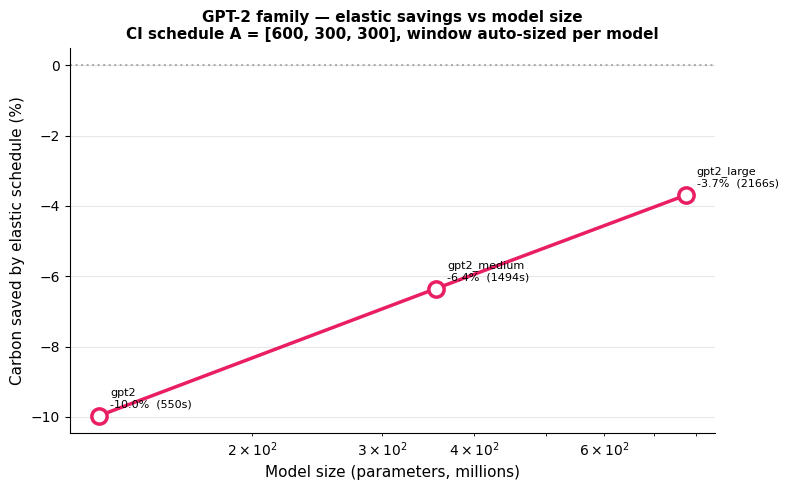


── Llama family  (A = [600, 300]) ──
llama_1b        | window=   960s | best fixed=   54.5g | schedule=   55.3g | saved= -1.5%
llama_2b        | window=  1371s | best fixed=   91.0g | schedule=   89.3g | saved= +1.8%
llama_3b        | window=  1386s | best fixed=  109.1g | schedule=   99.5g | saved= +8.8%


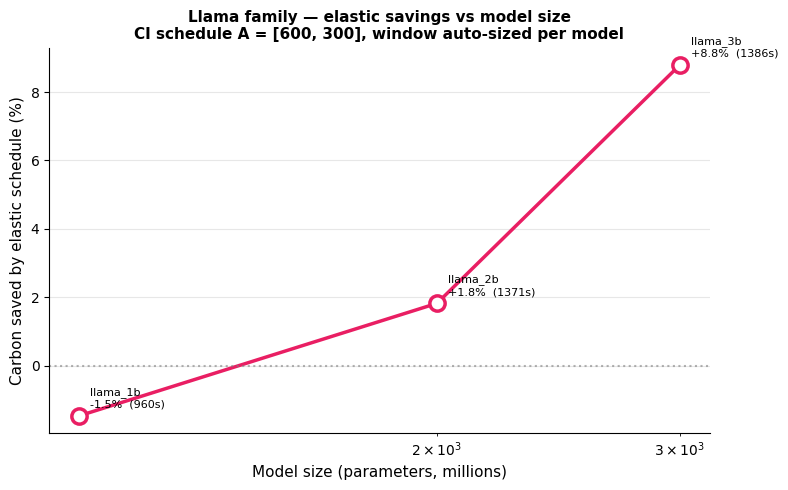

In [ ]:
# =====================================================================
# 15) Elastic Schedule Carbon Savings vs Model Size — per family
# =====================================================================
# Two plots: one for GPT-2 family, one for Llama family.
# Each family gets its own CI schedule A.
# Each model within a family gets its own window (slowest run).

MODEL_PARAMS_M = {
    "gpt2":         124,
    "gpt2_medium":  355,
    "gpt2_large":   774,
    "llama_1b":    1100,
    "llama_2b":    2000,
    "llama_3b":    3000,
}

FAMILIES = {
    "gpt2":  {
        "models": ["gpt2", "gpt2_medium", "gpt2_large"],
        "A":      [600, 300, 300],
        "title":  "GPT-2 family",
    },
    "llama": {
        "models": ["llama_1b", "llama_2b", "llama_3b"],
        "A":      [400, 100, 100],
        "title":  "Llama family",
    },
}

STATIC_FILES = [
    "elastic_tp1_pp1_dp4_power.csv",
    "elastic_tp4_pp1_dp1_power.csv",
    "elastic_tp1_pp4_dp1_power.csv",
    "elastic_tp2_pp2_dp1_power.csv",
    "elastic_tp2_pp1_dp2_power.csv",
    "elastic_tp1_pp2_dp2_power.csv",
]
SCHEDULE_FILE = "elastic_example_schedule_power.csv"

CROSS_PLOTS_DIR = os.path.join(BASE, "plots", "cross_model")
os.makedirs(CROSS_PLOTS_DIR, exist_ok=True)


def _load_runs(ddir, files):
    out = {}
    for f in files:
        p = os.path.join(ddir, f)
        if not os.path.exists(p):
            continue
        df = load_power_csv(p)
        if len(df) >= 2:
            out[f] = df
    return out


def _carbon_varying(df, A_family, schedule_duration_s):
    power = df["total_power_W"].to_numpy()
    ci = get_ci_schedule_wallclock(len(power), INTERVAL_SECONDS,
                                   A_family, schedule_duration_s)
    _, total = compute_carbon(power, ci, INTERVAL_SECONDS)
    return total


def _collect_family_rows(models, A_family):
    rows = []
    for m in sorted(models, key=lambda x: MODEL_PARAMS_M.get(x, 0)):
        ddir = os.path.join(BASE, "power_logs", m)
        if not os.path.isdir(ddir):
            print(f"[skip] {m}: no directory")
            continue

        static_runs = _load_runs(ddir, STATIC_FILES)
        sched_runs  = _load_runs(ddir, [SCHEDULE_FILE])
        if not static_runs or not sched_runs:
            print(f"[skip] {m}: missing runs")
            continue

        all_runs = {**static_runs, **sched_runs}
        sched_dur_s = max(len(df) for df in all_runs.values()) * INTERVAL_SECONDS

        static_carbons = [_carbon_varying(df, A_family, sched_dur_s)
                          for df in static_runs.values()]
        sched_carbon   = _carbon_varying(next(iter(sched_runs.values())),
                                         A_family, sched_dur_s)

        best_fixed = min(static_carbons)
        saving_pct = (best_fixed - sched_carbon) / best_fixed * 100

        rows.append({
            "model":        m,
            "params_M":     MODEL_PARAMS_M.get(m, 0),
            "sched_dur_s":  sched_dur_s,
            "best_fixed_g": best_fixed,
            "schedule_g":   sched_carbon,
            "saving_pct":   saving_pct,
        })
        print(f"{m:15s} | window={sched_dur_s:6.0f}s | "
              f"best fixed={best_fixed:7.1f}g | schedule={sched_carbon:7.1f}g | "
              f"saved={saving_pct:+5.1f}%")
    return rows


def _plot_family(rows, A_family, title, outfile):
    if len(rows) < 2:
        print(f"[skip plot] {title}: need ≥2 models, got {len(rows)}")
        return
    params  = [r["params_M"]    for r in rows]
    savings = [r["saving_pct"]  for r in rows]
    names   = [r["model"]       for r in rows]
    windows = [r["sched_dur_s"] for r in rows]

    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(params, savings, "o-", color=COLORS["schedule"],
            linewidth=2.5, markersize=11,
            markerfacecolor="white", markeredgewidth=2.5)
    for p, s, n, w in zip(params, savings, names, windows):
        ax.annotate(f"{n}\n{s:+.1f}%  ({w:.0f}s)", (p, s),
                    textcoords="offset points", xytext=(8, 6), fontsize=8)
    ax.axhline(0, color="gray", linestyle=":", alpha=0.6)
    ax.set_xscale("log")
    ax.set_xlabel("Model size (parameters, millions)", fontsize=11)
    ax.set_ylabel("Carbon saved by elastic schedule (%)", fontsize=11)
    ax.set_title(
        f"{title} — elastic savings vs model size\n"
        f"CI schedule A = {A_family}, window auto-sized per model",
        fontsize=11, fontweight="bold",
    )
    plt.tight_layout()
    plt.savefig(os.path.join(CROSS_PLOTS_DIR, outfile),
                dpi=150, bbox_inches="tight")
    plt.show()


# ── Run per family ───────────────────────────────────────────
for family_key, fam in FAMILIES.items():
    print(f"\n── {fam['title']}  (A = {fam['A']}) ──")
    rows = _collect_family_rows(fam["models"], fam["A"])
    _plot_family(rows, fam["A"], fam["title"],
                 f"savings_vs_model_size_{family_key}.png")

In [ ]:
# =====================================================================
# 11) Power Landscapes by Family — One Panel per Family
# =====================================================================
# For each model family, plot steady-state average power across the six
# valid (DP, TP, PP) configurations on a single node. Sizes within a
# family are shown as adjacent bars per config, so two patterns are
# visible at a glance: (a) the architecture-level config ranking, and
# (b) whether that ranking holds as the model scales up.

CONFIG_ORDER = [
    ("elastic_tp1_pp1_dp4_power.csv", "DP=4"),
    ("elastic_tp4_pp1_dp1_power.csv", "TP=4"),
    ("elastic_tp1_pp4_dp1_power.csv", "PP=4"),
    ("elastic_tp2_pp2_dp1_power.csv", "TP=2,PP=2"),
    ("elastic_tp2_pp1_dp2_power.csv", "TP=2,DP=2"),
    ("elastic_tp1_pp2_dp2_power.csv", "PP=2,DP=2"),
]

POWER_LANDSCAPE_FAMILIES = {
    "GPT-2":  ["gpt2", "gpt2_medium", "gpt2_large"],
    "Llama":  ["llama_1b", "llama_2b", "llama_3b"],
    "Pythia": ["pythia_410m", "pythia_1_4b", "pythia_2_8b"],
}

SIZE_LABELS = {
    "gpt2": "small (124M)", "gpt2_medium": "medium (355M)", "gpt2_large": "large (774M)",
    "llama_1b": "1B", "llama_2b": "2B", "llama_3b": "3B",
    "pythia_410m": "410M", "pythia_1_4b": "1.4B", "pythia_2_8b": "2.8B",
}

FAMILY_CMAPS = {"GPT-2": plt.cm.Blues, "Llama": plt.cm.Greens, "Pythia": plt.cm.Purples}


def _steady_avg_power(path, warmup_frac=0.2):
    """Steady-state mean total power (W). Returns None if file missing/too short."""
    if not os.path.exists(path):
        return None
    df = load_power_csv(path)
    if len(df) < 5:
        return None
    warmup = int(len(df) * warmup_frac)
    return df["total_power_W"].iloc[warmup:].mean()


# ── Collect: family -> {model: [power_per_config]} ───────────
landscape_data = {}
for fam_name, models in POWER_LANDSCAPE_FAMILIES.items():
    fam = {}
    for m in models:
        ddir = os.path.join(BASE, "power_logs", m)
        if not os.path.isdir(ddir):
            continue
        powers = [_steady_avg_power(os.path.join(ddir, fn))
                  for fn, _ in CONFIG_ORDER]
        if any(p is not None for p in powers):
            fam[m] = powers
    if fam:
        landscape_data[fam_name] = fam

# ── Plot: one panel per family ───────────────────────────────
if not landscape_data:
    print("No power logs found for any family — nothing to plot.")
else:
    n_fam = len(landscape_data)
    fig, axes = plt.subplots(1, n_fam, figsize=(5.0 * n_fam, 4.2))
    axes = np.atleast_1d(axes)

    cfg_labels = [lbl for _, lbl in CONFIG_ORDER]
    x = np.arange(len(cfg_labels))

    for ax, (fam_name, fam) in zip(axes, landscape_data.items()):
        sizes = list(fam.keys())
        n_sizes = len(sizes)
        bar_w = 0.8 / max(n_sizes, 1)
        cmap = FAMILY_CMAPS.get(fam_name, plt.cm.Greys)
        # Skip the lightest end so the smallest model's bars are still visible.
        shades = [cmap(0.45 + 0.45 * i / max(n_sizes - 1, 1)) for i in range(n_sizes)]

        for i, m in enumerate(sizes):
            powers = fam[m]
            offset = (i - (n_sizes - 1) / 2) * bar_w
            valid = [(xi + offset, p) for xi, p in zip(x, powers) if p is not None]
            if not valid:
                continue
            xs, ps = zip(*valid)
            ax.bar(xs, ps, bar_w, color=shades[i], edgecolor="white",
                   linewidth=0.5, label=SIZE_LABELS.get(m, m))

        ax.set_title(fam_name, fontsize=11, fontweight="bold")
        ax.set_xticks(x)
        ax.set_xticklabels(cfg_labels, fontsize=8, rotation=15, ha="right")
        ax.set_ylabel("Steady-state avg power (W)", fontsize=9)
        ax.tick_params(axis="y", labelsize=8)
        ax.legend(fontsize=7, frameon=False, loc="best")
        ax.grid(axis="y", alpha=0.3)

    fig.suptitle(
        "Power landscape across (DP, TP, PP) configurations",
        fontsize=11, fontweight="bold", y=1.02,
    )
    plt.tight_layout()

    out_dir = os.path.join(BASE, "plots", "cross_model")
    os.makedirs(out_dir, exist_ok=True)
    out_path = os.path.join(out_dir, "power_landscape_by_family.png")
    plt.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\nSaved: {out_path}")

    # ── Compact table for the log ────────────────────────────
    header = f"{'Family':8s} | {'Size':18s} | " + " | ".join(f"{lbl:>10s}" for lbl in cfg_labels)
    print("\n" + header)
    print("-" * len(header))
    for fam_name, fam in landscape_data.items():
        for m, powers in fam.items():
            cells = " | ".join(f"{p:10.1f}" if p is not None else f"{'—':>10s}" for p in powers)
            print(f"{fam_name:8s} | {SIZE_LABELS.get(m, m):18s} | {cells}")